In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
L = 5                                     # panjang lattice
N = L * L                                 # ukuran lattice
J = 1.0                                   # kuat interaksi
T = np.linspace(3.5, 1.5, 80)             # temperature

n_therm = 1000     # jumlah sweep
n_measure = 1000   # jumlah sample yg diambil

In [3]:
def random_spin_field():
    return np.random.choice([-1, 1], size=(L, L))

lattice = random_spin_field()
print(lattice)

[[-1 -1  1  1  1]
 [-1 -1 -1  1  1]
 [ 1 -1  1  1  1]
 [ 1  1  1  1  1]
 [-1  1  1  1  1]]


## Perubahan energi lokal

$$
s_{x,y}\longrightarrow-s_{x,y}
$$

Ada empat tetangga

$$
s_{x+1,y},\quad s_{x-1,y},\quad s_{x,y+1},\quad s_{x,y-1}
$$

Energi sebelum dan sesudah flip:

$$
\begin{aligned}E^{\mathrm{lama}}_{x,y}&=-Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)-hs_{x,y},\\[5pt]E^{\mathrm{baru}}_{x,y}&=-J(-s_{x,y})\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)-h(-s_{x,y})\\[3pt]&=Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)+hs_{x,y}.\end{aligned}
$$

$$
\begin{aligned}\Delta E&=E^{\mathrm{baru}}_{x,y}-E^{\mathrm{lama}}_{x,y}\\[4pt]&=Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)+hs_{x,y}\\[3pt]&\quad-\left[-Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)-hs_{x,y}\right]\\[4pt]&=2Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)+2hs_{x,y}\\[4pt]&=\boxed{2s_{x,y}\left[J\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)+h\right]}.\end{aligned}
$$

Tanpa medan luar:

$$
\boxed{\Delta E=2Js_{x,y}\left(s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}\right)}
$$

$n$ = jumlah tetangga sejajar dengan spin pusat.

$$
\begin{aligned}s_{x+1,y}+s_{x-1,y}+s_{x,y+1}+s_{x,y-1}&=ns_{x,y}+(4-n)(-s_{x,y})\\[3pt]&=ns_{x,y}-(4-n)s_{x,y}\\[3pt]&=[n-(4-n)]s_{x,y}\\[3pt]&=(2n-4)s_{x,y},\\[6pt]\Delta E&=2Js_{x,y}(2n-4)s_{x,y}\\[3pt]&=\boxed{4J(n-2)},\qquad s_{x,y}^2=1.\end{aligned}
$$

In [4]:
def delta_energy(lattice, x, y):
    L = lattice.shape[0]
    spin = lattice[x, y]
    neighbors = lattice[(x+1) % L, y] + lattice[(x-1) % L, y] + lattice[x, (y+1) % L] + lattice[x, (y-1) % L]
    return 2 * J * spin * neighbors

$$
M=\sum_{x,y}s_{x,y}
$$

In [5]:
def magnetization(lattice):
    return np.sum(lattice)


$$
p_\mu=\frac{e^{-\beta E_\mu}}{Z},\qquad\beta=\frac{1}{k_BT}
$$

global balance:

$$
\begin{gathered}\sum_\nu P(\mu\to\nu)=1,\\[6pt]\begin{aligned}\sum_\nu p_\mu P(\mu\to\nu)&=\sum_\nu p_\nu P(\nu\to\mu),\\[5pt]p_\mu\sum_\nu P(\mu\to\nu)&=\sum_\nu p_\nu P(\nu\to\mu),\\[5pt]p_\mu&=\sum_\nu p_\nu P(\nu\to\mu).\end{aligned}\end{gathered}
$$

Detail balance:

$$
p_\mu P(\mu\to\nu)=p_\nu P(\nu\to\mu)
$$

$$
\begin{aligned}\frac{P(\mu\to\nu)}{P(\nu\to\mu)}&=\frac{p_\nu}{p_\mu}\\[6pt]&=\frac{e^{-\beta E_\nu}/Z}{e^{-\beta E_\mu}/Z}\\[6pt]&=\frac{e^{-\beta E_\nu}}{Z}\frac{Z}{e^{-\beta E_\mu}}\\[6pt]&=e^{-\beta E_\nu}e^{\beta E_\mu}\\[4pt]&=e^{-\beta(E_\nu-E_\mu)}\\[4pt]&=\boxed{e^{-\beta\Delta E}},\qquad\Delta E=E_\nu-E_\mu.\end{aligned}
$$

## Algoritma Metropolis

$$
P(\mu\to\nu)=g(\mu\to\nu)A(\mu\to\nu)
$$

Usulan simetris:

$$
g(\mu\to\nu)=g(\nu\to\mu)
$$

$$
\frac{A(\mu\to\nu)}{A(\nu\to\mu)}=e^{-\beta\Delta E}
$$

$$
\boxed{P_{\mathrm{acc}}=A(\mu\to\nu)=\min\left(1,e^{-\beta\Delta E}\right)}
$$

Verifikasi dua kasus:

$$
\Delta E\le0:\quad A(\mu\to\nu)=1,\quad A(\nu\to\mu)=e^{\beta\Delta E},\quad\frac{A(\mu\to\nu)}{A(\nu\to\mu)}=e^{-\beta\Delta E}
$$

$$
\Delta E>0:\quad A(\mu\to\nu)=e^{-\beta\Delta E},\quad A(\nu\to\mu)=1,\quad\frac{A(\mu\to\nu)}{A(\nu\to\mu)}=e^{-\beta\Delta E}
$$

In [6]:
def metropolis_step(lattice, T):
    x = np.random.randint(0, L)
    y = np.random.randint(0, L)

    dE = delta_energy(lattice, x, y)

    if dE <= 0 or np.random.random() < np.exp(-dE / T):
      lattice[x, y] *= -1

$$
E=-J\sum_{x,y}s_{x,y}\left(s_{x,y+1}+s_{x+1,y}\right)
$$


In [7]:
def total_energy(lattice):
    E = 0.0

    for x in range(L):
        for y in range(L):
            spin = lattice[x, y]
            right = lattice[x, (y + 1) % L]
            down = lattice[(x + 1) % L, y]
            E -= J * spin * (right + down)

    return E

In [8]:
def simulate(lattice, temp):
    energies = []
    magnetizations = []

    for sweep in range(n_therm + n_measure):
        for i in range(L * L):
          metropolis_step(lattice, temp)

        if sweep >= n_therm:
            energies.append(total_energy(lattice))
            magnetizations.append(magnetization(lattice))

    return np.array(energies), np.array(magnetizations)

In [9]:
# print(simulate(lattice, 5))

def simulate_temp(lattice, T):
    c_vs_t = []
    kai_vs_t = []

    for t in T:
        energies, magnetizations = simulate(lattice, t)

        E_mean = np.mean(energies)
        E_2_mean = np.mean(energies ** 2)

        M_abs_mean = np.mean(np.abs(magnetizations))
        M_2_mean = np.mean(magnetizations ** 2)

        c = (E_2_mean - E_mean ** 2) / (N * t ** 2)

        Kai = (M_2_mean - M_abs_mean ** 2) / (N * t)

        c_vs_t.append(c)
        kai_vs_t.append(Kai)

    return np.array(c_vs_t), np.array(kai_vs_t)


c_vs_t, kai_vs_t = simulate_temp(lattice, T)

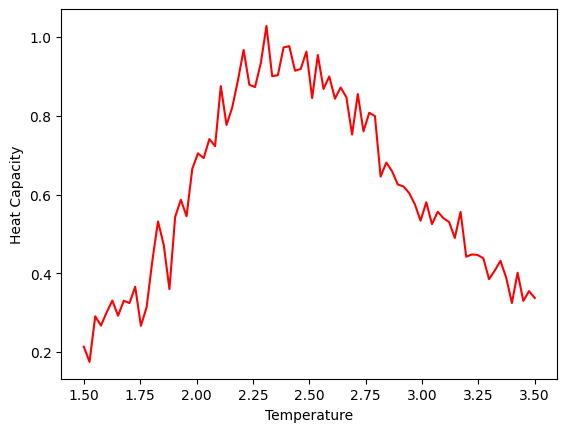

In [10]:
plt.plot(T, c_vs_t, color='red')
plt.xlabel('Temperature')
plt.ylabel('Heat Capacity')
plt.show()

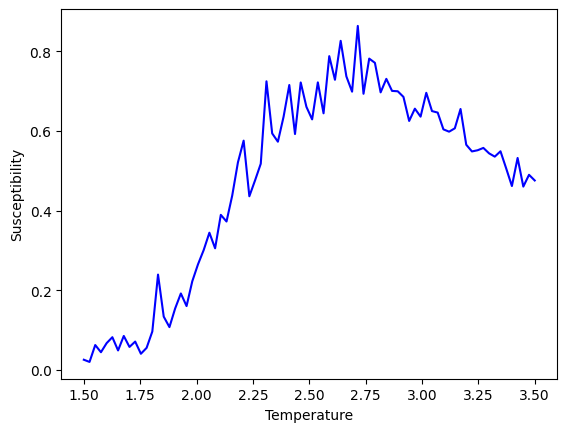

In [11]:
plt.plot(T, kai_vs_t, color='blue')
plt.xlabel('Temperature')
plt.ylabel('Susceptibility')
plt.show()

In [12]:
print(lattice)

[[-1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1]]
